In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
import joblib # Used for saving and loading the trained model
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the datasets we need to build the full feature matrix
df_exp = pd.read_csv('../data/cleaned_experimental_data_combined.csv')
df_desc = pd.read_csv('../data/orca_descriptors_individual.csv')
df_atoms = pd.read_csv('../data/ions_with_atomic_counts.csv')

print("All source files loaded.")

All source files loaded.


In [3]:
# This cell contains the complete merging logic from notebook 07
def standardize_name(series):
    return series.str.strip().str.replace(r'[+\[\]()-]', '', regex=True)

# 1. Combine all feature files
df_atom_counts_only = df_atoms.drop(columns=['ion_name', 'ion_type', 'smiles'])
df_all_features = pd.merge(df_desc, df_atom_counts_only, on='ion_abbreviation', how='left')
df_all_features = pd.merge(df_all_features, df_atoms[['ion_abbreviation', 'ion_name', 'ion_type']], on='ion_abbreviation', how='left')

# 2. Prepare for merging
df_all_features['merge_key'] = standardize_name(df_all_features['ion_abbreviation'])
df_exp['cation_merge_key'] = standardize_name(df_exp['cation'])
df_exp['anion_merge_key'] = standardize_name(df_exp['anion'])

df_cat_features = df_all_features[df_all_features['ion_type'] == 'cation'].copy()
df_an_features = df_all_features[df_all_features['ion_type'] == 'anion'].copy()

df_cat_features.columns = ['cation_' + col if col not in ['ion_abbreviation', 'merge_key'] else col for col in df_cat_features.columns]
df_an_features.columns = ['anion_' + col if col not in ['ion_abbreviation', 'merge_key'] else col for col in df_an_features.columns]

# 3. Perform Merges
df_merged = pd.merge(df_exp, df_cat_features, left_on='cation_merge_key', right_on='merge_key', how='inner')
df_final = pd.merge(df_merged, df_an_features, left_on='anion_merge_key', right_on='merge_key', how='inner')
df_final.fillna(0, inplace=True)

# 4. Define our final X and y
target_col = "CO2_solubility"
ignore_cols = ["cation", "cation_ion_name", "anion", "anion_ion_name", 'CO2_solubility']
feature_cols = [col for col in df_final.columns if col not in ignore_cols and not 'merge_key' in col and not 'ion_abbreviation' in col and not '_ion_type' in col]

X_train_full = df_final[feature_cols]
y_train_full = df_final[target_col]

print(f"Full training dataset created with {len(X_train_full)} samples.")

Full training dataset created with 11256 samples.


In [4]:
# 1. Create and fit the scaler on the full dataset
scaler = StandardScaler()
X_train_full_scaled = scaler.fit_transform(X_train_full)

# 2. Create and train the final Random Forest model
final_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
print("--- Training final model on 100% of the data... ---")
final_model.fit(X_train_full_scaled, y_train_full)
print("--- Final model training complete. ---")

# 3. Save the trained model and scaler to disk for future use
joblib.dump(final_model, 'final_rf_model.joblib')
joblib.dump(scaler, 'final_scaler.joblib')
joblib.dump(feature_cols, 'final_feature_list.joblib') # Save the feature list

print("Final model, scaler, and feature list have been saved to disk.")

--- Training final model on 100% of the data... ---
--- Final model training complete. ---
Final model, scaler, and feature list have been saved to disk.


In [5]:
# --- This is where you define your new, hypothetical ILs ---
# You can add any cation/anion abbreviation that you have descriptors for.
# Let's try to find the best anion for [BMIM] and the best cation for [Tf2N].

candidate_cations = ['[BMIM]', '[EMIM]', '[HMIM]', '[OMIM]', '[PMIM]']
candidate_anions = ['[Tf2N]', '[BF4]', '[PF6]', '[DCA]', '[SCN]']

# Create a dataframe of new combinations
from itertools import product
new_pairs = list(product(candidate_cations, candidate_anions))
df_candidates = pd.DataFrame(new_pairs, columns=['cation', 'anion'])

print(f"Created a list of {len(df_candidates)} new candidate ILs to screen.")
df_candidates.head()

Created a list of 25 new candidate ILs to screen.


,cation,anion
0,[BMIM],[Tf2N]
1,[BMIM],[BF4]
2,[BMIM],[PF6]
3,[BMIM],[DCA]
4,[BMIM],[SCN]


In [6]:
# We now repeat the merging process for our new candidates

# 1. Load the feature data
df_desc = pd.read_csv('../data/orca_descriptors_individual.csv')
df_atoms = pd.read_csv('../data/ions_with_atomic_counts.csv')

# 2. Combine all features
df_atom_counts_only = df_atoms.drop(columns=['ion_name', 'ion_type', 'smiles'])
df_all_features = pd.merge(df_desc, df_atom_counts_only, on='ion_abbreviation', how='left')
df_all_features = pd.merge(df_all_features, df_atoms[['ion_abbreviation', 'ion_name', 'ion_type']], on='ion_abbreviation', how='left')

# 3. Prepare for merging
df_all_features['merge_key'] = standardize_name(df_all_features['ion_abbreviation'])
df_candidates['cation_merge_key'] = standardize_name(df_candidates['cation'])
df_candidates['anion_merge_key'] = standardize_name(df_candidates['anion'])

df_cat_features = df_all_features[df_all_features['ion_type'] == 'cation'].copy()
df_an_features = df_all_features[df_all_features['ion_type'] == 'anion'].copy()

df_cat_features.columns = ['cation_' + col if col not in ['ion_abbreviation', 'merge_key'] else col for col in df_cat_features.columns]
df_an_features.columns = ['anion_' + col if col not in ['ion_abbreviation', 'merge_key'] else col for col in df_an_features.columns]

# 4. Perform Merges
df_merged = pd.merge(df_candidates, df_cat_features, left_on='cation_merge_key', right_on='merge_key', how='inner')
df_predict = pd.merge(df_merged, df_an_features, left_on='anion_merge_key', right_on='merge_key', how='inner')
df_predict.fillna(0, inplace=True)

print("Candidate feature matrix built.")

Candidate feature matrix built.


In [7]:
# --- Load our saved model, scaler, and feature list ---
model = joblib.load('final_rf_model.joblib')
scaler = joblib.load('final_scaler.joblib')
feature_cols = joblib.load('final_feature_list.joblib')

# --- Define the experimental conditions we want to test ---
# Let's test at 323.15 K (50 C) and a high pressure of 5000 kPa
T_condition = 323.15
P_condition = 5000

# Add these conditions to our candidate dataframe
df_predict['Temperature_K'] = T_condition
df_predict['Pressure_kPa'] = P_condition

# --- Prepare the final feature matrix for prediction ---
# Ensure the columns are in the exact same order as when we trained
X_predict = df_predict[feature_cols]

# Scale the features using the *loaded* scaler
X_predict_scaled = scaler.transform(X_predict)

# --- MAKE PREDICTIONS ---
predictions = model.predict(X_predict_scaled)
df_predict['Predicted_CO2_Solubility'] = predictions

print(f"Predictions complete for {len(df_predict)} ILs at T={T_condition} K and P={P_condition} kPa.")

Predictions complete for 25 ILs at T=323.15 K and P=5000 kPa.



--- Top 10 Predicted ILs for CO2 Capture ---
    cation   anion  Predicted_CO2_Solubility
15  [OMIM]  [Tf2N]                  0.642774
10  [HMIM]  [Tf2N]                  0.549153
0   [BMIM]  [Tf2N]                  0.526077
20  [PMIM]  [Tf2N]                  0.520864
5   [EMIM]  [Tf2N]                  0.516046
17  [OMIM]   [PF6]                  0.436529
12  [HMIM]   [PF6]                  0.425360
18  [OMIM]   [DCA]                  0.418861
13  [HMIM]   [DCA]                  0.417182
16  [OMIM]   [BF4]                  0.394396


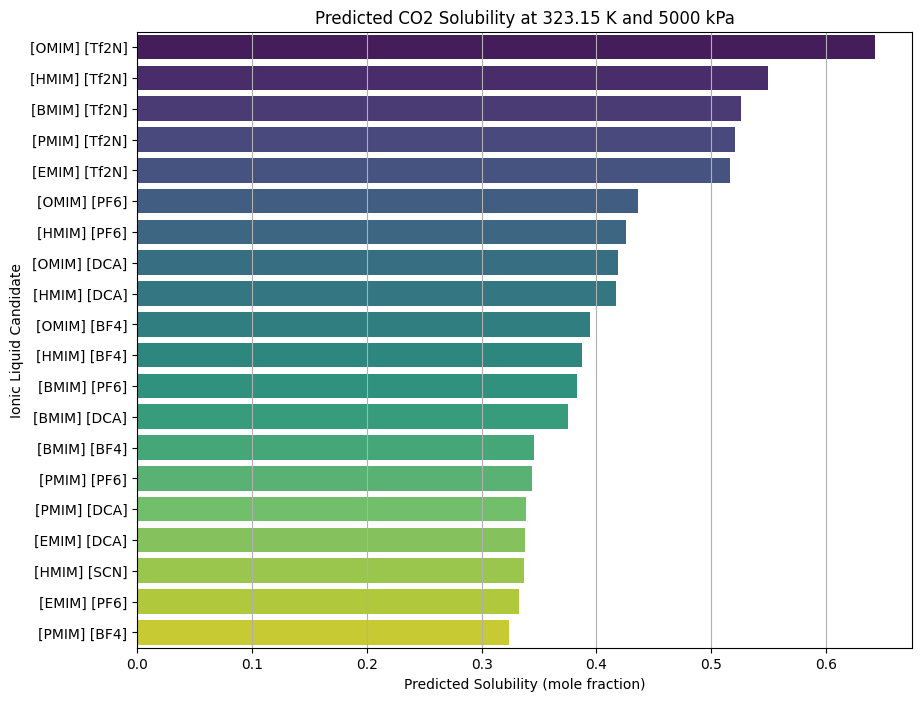

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Sort the results to find the best candidates ---
df_final_results = df_predict[['cation', 'anion', 'Predicted_CO2_Solubility']]
df_sorted = df_final_results.sort_values(by='Predicted_CO2_Solubility', ascending=False)

print("\n--- Top 10 Predicted ILs for CO2 Capture ---")
print(df_sorted.head(10))

# --- Plot the results ---
plt.figure(figsize=(10, 8))
sns.barplot(
    data=df_sorted.head(20), 
    y=df_sorted.head(20).apply(lambda x: f"{x['cation']} {x['anion']}", axis=1), # Create a 'CationAnion' label
    x='Predicted_CO2_Solubility',
    palette='viridis'
)
plt.title(f'Predicted CO2 Solubility at {T_condition} K and {P_condition} kPa')
plt.xlabel('Predicted Solubility (mole fraction)')
plt.ylabel('Ionic Liquid Candidate')
plt.grid(True, axis='x')
plt.show()